In [1]:
import dafeaero as da

In [2]:
def generate_airfoil(a, b, c):
    return da.Airfoil.naca(f"{a}{b}{c:02d}")

gene_space = (
    (0, 7),
    (1, 8),
    da.ParameterSequence(6, 15),
)

flap_settings = da.optimization.OptimizationFlapSettings(
    da.ParameterSequence(5, 35, 5), da.ParameterSequence(0.75)
)
settings = da.optimization.MinCruiseDragOptSettings(9, 14, 5, 9, 0.85, flap_settings)

result = da.optimization.launch_ga_optimization(
    generate_airfoil,
    gene_space,
    da.optimization.ObjectiveFunction.MIN_CRUISE_DRAG,
    settings
)

Ошибка расчёта для генов (4, 7, 8)
Traceback (most recent call last):
  File "c:\Users\hp\OneDrive\Рабочий стол\Morphing_Wing_Instrument\dafeaero\facade\airfoil.py", line 178, in polar
    polar_file = run_xfoil(cmd, XFOIL_EXE_PATH, workdir)
  File "c:\Users\hp\OneDrive\Рабочий стол\Morphing_Wing_Instrument\dafeaero\xfoilpy\run_xfoil.py", line 53, in run_xfoil
    code = run_hidden(exe, cmd_file, work_dir, timeout=XFOIL_TIMEOUT)
  File "c:\Users\hp\OneDrive\Рабочий стол\Morphing_Wing_Instrument\dafeaero\xfoilpy\hidden_process.py", line 88, in run_hidden
    raise subprocess.TimeoutExpired(str(exe), timeout)
subprocess.TimeoutExpired: Command 'C:\Users\hp\OneDrive\Рабочий стол\Morphing_Wing_Instrument\dafeaero\xfoilpy\xfoil_software\xfoil.exe' timed out after 120 seconds

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\shutil.py", line 625, in _rmtree_unsafe
    os.unl

In [3]:
print(result)

{'genes': [3, 3, 6], 'airfoil': Airfoil('NACA 3306', n_points=161), 'fitness': np.float64(0.5447249099896605), 'drag_X': np.float64(1.8357880040662564), 'ga_instance': <pygad.pygad.GA object at 0x00000152F0FE9D30>}


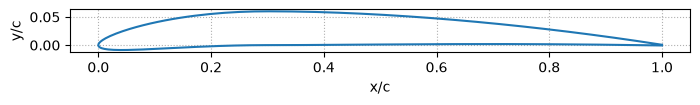

<Axes: xlabel='x/c', ylabel='y/c'>

In [4]:
naca3306 = da.Airfoil.naca("3306")
naca3306.plot()